# Chapter 22: Adverse Selection, Lemons, Signaling, and Screening

This notebook reruns four worked examples from the chapter: the lemons market for used vans, an insurance pool that loses its low risks, a credential that separates worker types, and a deductible menu that sorts buyers. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def lemons_equilibrium(counts, seller_vals, buyer_vals):
    """akerlof-lemons-equilibrium: two-quality market (low, high) with unobserved quality.
    counts = (n_low, n_high), seller_vals = owners' reservation values, buyer_vals = buyers' values.
    The pooled offer is the count-weighted buyer value; if it is below the high owners' value
    (strictly), high owners withdraw and price falls to the low buyer value. A tie keeps the pool.
    Book (ch022): 50/50, sellers 4,000 and 11,000, buyers 6,000 and 14,000 give pooled offer
    10,000, equilibrium price 6,000, 50 low trades and lost surplus 50(14,000 - 11,000) = 150,000."""
    (nL, nH), (sL, sH), (bL, bH) = counts, seller_vals, buyer_vals
    pooled = (nL * bL + nH * bH) / (nL + nH)
    pool_survives = pooled >= sH
    price = pooled if pool_survives else bL
    trades_low = nL if price >= sL else 0
    trades_high = nH if pool_survives else 0
    lost = (nL - trades_low) * (bL - sL) + (nH - trades_high) * (bH - sH)
    return {"pooled": pooled, "pool_survives": pool_survives, "tie": pooled == sH, "price": price,
            "trades_low": trades_low, "trades_high": trades_high, "lost_surplus": lost}


def adverse_selection_premium(claims, wtp, counts, class_cost=0.0):
    """asymmetric-information-adverse-selection: pooled premium spiral and classified premiums.
    claims = expected claims (low, high), wtp = maximum willingness to pay, counts = group sizes.
    Pooled premium pi_0 is the count-weighted claim; if low risks refuse (wtp < premium), the
    premium becomes the high-risk claim. Classification charges each group claim + class_cost.
    Book (ch022): claims 1,000 and 3,000, wtp 1,300 and 3,300, 50 each give pi_0 = 2,000,
    pi_1 = 3,000; classification at 100 gives 1,100 and 3,100 and costs 100(100) = 10,000;
    at 400 the low premium 1,400 exceeds 1,300."""
    (cL, cH), (wL, wH), (nL, nH) = claims, wtp, counts
    pooled = (nL * cL + nH * cH) / (nL + nH)
    low_buys_pooled = wL >= pooled
    eq_premium = pooled if low_buys_pooled else cH
    prem_L, prem_H = cL + class_cost, cH + class_cost
    return {"pooled": pooled, "low_buys_pooled": low_buys_pooled, "equilibrium": eq_premium,
            "takeup_low_pooled": nL if low_buys_pooled else 0, "high_buys": wH >= eq_premium,
            "class_premium_low": prem_L, "class_premium_high": prem_H,
            "class_low_buys": wL >= prem_L, "class_high_buys": wH >= prem_H,
            "takeup_low_classified": nL if wL >= prem_L else 0,
            "class_total_cost": (nL + nH) * class_cost}


def signaling_ic(wH, wL, cH, cL):
    """costly-signaling: incentive checks for a separating credential.
    High type signals if wH - cH > wL; low type stays out if wH - cL <= wL (equality is a tie:
    the low type is indifferent and separation holds only weakly).
    Book (ch022): 100,000 - 10,000 = 90,000 > 60,000 and 100,000 - 50,000 = 50,000 < 60,000
    separate; at cL = 30,000 imitation pays 70,000 > 60,000."""
    high_net, low_imit = wH - cH, wH - cL
    high_ok = high_net > wL
    low_tie = abs(low_imit - wL) <= 1e-9
    low_ok = low_imit < wL or low_tie
    return {"high_net": high_net, "low_imitation": low_imit, "high_ok": high_ok, "low_ok": low_ok,
            "low_tie": low_tie, "separates": high_ok and low_ok, "breakeven_cL": wH - wL}


def screening_choice(premiums, deductibles, probs):
    """screening-self-selection: expected monetary cost of each plan for each risk type.
    premiums, deductibles: one entry per plan (Plan D, Plan F); probs: loss probability per type.
    Cost = premium + p x deductible. Returns costs[type][plan], each type's choice (None on a tie)
    and whether the menu separates (types choose different plans).
    Book (ch022): Plan D 225 / 500, Plan F 420 / 0, p = 0.10 and 0.40 give 275 and 425
    (separates); premium 175 gives 225 and 375 (both choose D)."""
    costs = [[pr + p * d for pr, d in zip(premiums, deductibles)] for p in probs]
    choices = []
    for row in costs:
        best = min(row)
        winners = [i for i, c in enumerate(row) if abs(c - best) <= 1e-9]
        choices.append(winners[0] if len(winners) == 1 else None)
    separates = None not in choices and len(set(choices)) == len(choices)
    return {"costs": costs, "choices": choices, "separates": separates}


plt.rcParams.update(HOUSE_RC)


information = SimpleNamespace(lemons_equilibrium=lemons_equilibrium, adverse_selection_premium=adverse_selection_premium, signaling_ic=signaling_ic, screening_choice=screening_choice)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'akerlof-lemons-equilibrium': {'counts': (50, 50),
                                'seller_vals': (4000, 11000),
                                'buyer_vals': (6000, 14000),
                                'pooled': 10000,
                                'price': 6000,
                                'trades_low': 50,
                                'lost_surplus': 150000},
 'asymmetric-information-adverse-selection': {'claims': (1000, 3000),
                                              'wtp': (1300, 3300),
                                              'counts': (50, 50),
                                              'pooled': 2000,
                                              'equilibrium': 3000,
                                              'class_cost': 100,
                                              'class_premiums': (1100, 3100),
                                              'class_total': 10000,
                                              'class_cost_high': 400,
                                              'class_premium_low_high': 1400},
 'costly-signaling': {'wH': 100000,
                      'wL': 60000,
                      'cH': 10000,
                      'cL': 50000,
                      'high_net': 90000,
                      'low_imitation': 50000,
                      'cL_low': 30000,
                      'low_imitation_low': 70000},
 'screening-self-selection': {'loss': 1000,
                              'probs': (0.1, 0.4),
                              'plan_F': 420,
                              'plan_D_premium': 225,
                              'plan_D_deductible': 500,
                              'low_D': 275,
                              'high_D': 425,
                              'premium_cut': 175,
                              'low_D_cut': 225,
                              'high_D_cut': 375},
 'constructed': {'akerlof-lemons-equilibrium': {'sH': [9000, 13000], 'share': [0.3, 0.7]},
                 'asymmetric-information-adverse-selection': {'wL': [1800, 2100],
                                                              'class_cost': [0]},
                 'costly-signaling': {'cL': [40000], 'cH': [45000]},
                 'screening-self-selection': {'premium': [250], 'deductible': [700]}}}


def lemons_picture(s_high=11_000, share=0.5):
    nH = round(100 * share)
    nL = 100 - nH
    res = information.lemons_equilibrium((nL, nH), (4_000, s_high), (6_000, 14_000))
    fig, ax = new_figure()
    bar_compare(ax, ["Pooled offer", "High owner value", "Market price"],
                [res["pooled"], s_high, res["price"]], colors=["navy", "gold", "teal"],
                value_labels=[money(res["pooled"], 0), money(s_high, 0), money(res["price"], 0)],
                ylabel="Dollars per van", xlabel="Price or value")
    ax.set_ylim(0, 16_500)
    ax.axhline(4_000, color=PALETTE["grey"], linestyle="dashed", linewidth=1.4, label="low owner value \\$4,000")
    ax.legend(loc="upper right", frameon=False)
    p_txt = f"{num(1 - share, 1)}(6,000) + {num(share, 1)}(14,000) = {num(res['pooled'], 0)}"
    if res["pool_survives"]:
        verdict = (f"The pooled offer {num(res['pooled'], 0)} is at least the high owners' {num(s_high, 0)}, so all "
                   f"100 vans trade at {num(res['pooled'], 0)} and no surplus is lost.")
        trades = "all 100 vans"
        steps = [f"Pooled offer = {p_txt}", f"{num(res['pooled'], 0)} >= {num(s_high, 0)}: high owners sell",
                 "Every van trades; lost surplus = 0"]
    else:
        verdict = (f"The pooled offer {num(res['pooled'], 0)} is below the high owners' {num(s_high, 0)}, so they keep "
                   f"their vans. Buyers price the remaining low-quality pool at 6,000 and {nL} low vans trade. "
                   f"Lost surplus is {nH}(14,000 - {num(s_high, 0)}) = {num(res['lost_surplus'], 0)}.")
        trades = f"{nL} low-quality vans"
        steps = [f"Pooled offer = {p_txt}", f"{num(res['pooled'], 0)} < {num(s_high, 0)}: high owners withdraw",
                 "Price falls to the low-quality buyer value 6,000 (above the 4,000 reservation)",
                 f"Lost surplus = {nH}(14,000 - {num(s_high, 0)}) = {num(res['lost_surplus'], 0)}"]
    metrics = {"Pooled offer": money(res["pooled"], 0), "Equilibrium price": money(res["price"], 0),
               "Vans that trade": trades, "Lost surplus": money(res["lost_surplus"], 0)}
    interp = f"With {nH} high-quality and {nL} low-quality vans, the pooled offer is {p_txt}. {verdict}"
    alt = (f"Bars for the pooled offer {num(res['pooled'], 0)}, the high owners' value {num(s_high, 0)} and the "
           f"market price {num(res['price'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def spiral_picture(w_low=1_300, cc=100):
    res = information.adverse_selection_premium((1_000, 3_000), (w_low, 3_300), (50, 50), cc)
    fig, ax = new_figure()
    vals = [res["pooled"], res["equilibrium"], res["class_premium_low"], res["class_premium_high"]]
    bar_compare(ax, ["Pooled", "After exit", "Classified low", "Classified high"], vals,
                colors=["navy", "gold", "teal", "terracotta"], value_labels=[money(v, 0) for v in vals],
                ylabel="Premium ($)", xlabel="Premium schedule")
    ax.set_ylim(0, 4_200)
    for t in ax.texts:  # keep value labels legible where a reference line crosses them
        t.set_bbox(dict(facecolor="white", edgecolor="none", pad=1.0))
        t.set_zorder(5)
    ax.axhline(w_low, color=PALETTE["teal"], linestyle="dashed", linewidth=1.4,
               label=f"low-risk maximum \\${num(w_low, 0)}")
    ax.axhline(3_300, color=PALETTE["terracotta"], linestyle="dotted", linewidth=1.4, label="high-risk maximum \\$3,300")
    ax.legend(loc="upper left", frameon=False)
    pooled_txt = f"(50(1,000) + 50(3,000)) / 100 = {num(res['pooled'], 0)}"
    if res["low_buys_pooled"]:
        pool_line = (f"Low risks pay up to {num(w_low, 0)} >= {num(res['pooled'], 0)}, so they stay and the pooled "
                     f"premium holds at {num(res['pooled'], 0)}.")
    else:
        pool_line = (f"Low risks pay at most {num(w_low, 0)} < {num(res['pooled'], 0)}, so they leave and the premium "
                     f"rises to the high-risk claim, 3,000.")
    cls = (f"Classification sets premiums 1,000 + {num(cc, 0)} = {num(res['class_premium_low'], 0)} and 3,000 + "
           f"{num(cc, 0)} = {num(res['class_premium_high'], 0)}; low risks "
           + ("enroll" if res["class_low_buys"] else "still stay out")
           + f" ({num(res['class_premium_low'], 0)} {'<=' if res['class_low_buys'] else '>'} {num(w_low, 0)}) and "
           f"high risks {'enroll' if res['class_high_buys'] else 'drop out'} ({num(res['class_premium_high'], 0)} "
           f"{'<=' if res['class_high_buys'] else '>'} 3,300). "
           f"It uses 100({num(cc, 0)}) = {num(res['class_total_cost'], 0)} of resources.")
    metrics = {"Pooled premium": money(res["pooled"], 0), "Equilibrium premium": money(res["equilibrium"], 0),
               "Low-risk take-up, pooled": str(res["takeup_low_pooled"]),
               "Low-risk take-up, classified": str(res["takeup_low_classified"]),
               "Classification cost": money(res["class_total_cost"], 0)}
    interp = f"Pooled premium = {pooled_txt}. {pool_line} {cls}"
    steps = [f"Pooled premium = {pooled_txt}",
             f"Low risks: {num(w_low, 0)} {'>=' if res['low_buys_pooled'] else '<'} {num(res['pooled'], 0)}, "
             f"equilibrium premium {num(res['equilibrium'], 0)}",
             f"Classified low premium = 1,000 + {num(cc, 0)} = {num(res['class_premium_low'], 0)}",
             f"Classification cost = 100({num(cc, 0)}) = {num(res['class_total_cost'], 0)}"]
    alt = (f"Premium bars: pooled {num(res['pooled'], 0)}, after exit {num(res['equilibrium'], 0)}, classified "
           f"{num(res['class_premium_low'], 0)} and {num(res['class_premium_high'], 0)}, with the low-risk "
           f"maximum at {num(w_low, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def signal_picture(c_low=50_000, c_high=10_000):
    res = information.signaling_ic(100_000, 60_000, c_high, c_low)
    fig, ax = new_figure()
    vals = [res["high_net"], 60_000, res["low_imitation"], 60_000]
    bar_compare(ax, ["High: signal", "High: no signal", "Low: imitate", "Low: no signal"], vals,
                colors=["navy", "grey", "terracotta", "grey"], value_labels=[money(v, 0) for v in vals],
                ylabel="Net payoff ($)", xlabel="Type and choice")
    ax.set_ylim(0, 110_000)
    if res["separates"]:
        verdict = ("The credential separates the types, weakly: the low type is exactly indifferent."
                   if res["low_tie"] else "The credential separates the types.")
    elif not res["high_ok"]:
        verdict = "No separation: the high type gains nothing from the credential."
    else:
        verdict = "No separation: the low type gains by imitating."
    rel_h = ">" if res["high_ok"] else "<="
    rel_l = "=" if res["low_tie"] else ("<" if res["low_ok"] else ">")
    metrics = {"High type net with signal": money(res["high_net"], 0),
               "Low type payoff from imitation": money(res["low_imitation"], 0),
               "Separating": ("yes, weakly (low type indifferent)" if res["separates"] and res["low_tie"]
                              else "yes" if res["separates"] else "no")}
    interp = (f"High type: 100,000 - {num(c_high, 0)} = {num(res['high_net'], 0)} {rel_h} 60,000. Low type imitating: "
              f"100,000 - {num(c_low, 0)} = {num(res['low_imitation'], 0)} {rel_l} 60,000. {verdict} Imitation breaks "
              f"even at a low-type cost of 100,000 - 60,000 = 40,000.")
    steps = [f"High: 100,000 - {num(c_high, 0)} = {num(res['high_net'], 0)} {rel_h} 60,000",
             f"Low: 100,000 - {num(c_low, 0)} = {num(res['low_imitation'], 0)} {rel_l} 60,000",
             f"Separating: {metrics['Separating']}"]
    alt = (f"Payoff bars: high type {num(res['high_net'], 0)} with the credential, low type "
           f"{num(res['low_imitation'], 0)} if it imitates, both against 60,000 without it.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def menu_picture(prem=225, ded=500):
    res = information.screening_choice((prem, 420), (ded, 0), (0.10, 0.40))
    (lD, lF), (hD, hF) = res["costs"]
    fig, ax = new_figure()
    vals = [lD, lF, hD, hF]
    bar_compare(ax, ["Low risk: D", "Low risk: F", "High risk: D", "High risk: F"], vals,
                colors=["teal", "grey", "terracotta", "grey"], value_labels=[money(v, 0) for v in vals],
                ylabel="Expected cost ($)", xlabel="Risk type and plan")
    ax.set_ylim(0, 640)
    name = {0: "Plan D", 1: "Plan F", None: "tie"}
    cl, ch = name[res["choices"][0]], name[res["choices"][1]]
    metrics = {"Low risk cost under D": money(lD, 0), "High risk cost under D": money(hD, 0),
               "Low risk chooses": cl, "High risk chooses": ch, "Separating": "yes" if res["separates"] else "no"}
    verdict = ("The menu separates: each type picks a different plan." if res["separates"]
               else "The menu does not separate: both types pick the same plan.")
    interp = (f"Low risk under D: {num(prem, 0)} + 0.10({num(ded, 0)}) = {num(lD, 0)} against 420, so it chooses "
              f"{cl}. High risk under D: {num(prem, 0)} + 0.40({num(ded, 0)}) = {num(hD, 0)} against 420, so it "
              f"chooses {ch}. {verdict}")
    steps = [f"Low: {num(prem, 0)} + 0.10({num(ded, 0)}) = {num(lD, 0)} {'<' if lD < 420 else '>'} 420, {cl}",
             f"High: {num(prem, 0)} + 0.40({num(ded, 0)}) = {num(hD, 0)} {'<' if hD < 420 else '>'} 420, {ch}",
             f"Separating: {metrics['Separating']}"]
    alt = (f"Expected cost bars: low risk {num(lD, 0)} under Plan D and 420 under Plan F; high risk {num(hD, 0)} "
           f"under Plan D and 420 under Plan F.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Akerlof lemons equilibrium

Fifty low and fifty high-quality vans; owners value them at \$4,000 and \$11,000, buyers at \$6,000 and \$14,000.

$$0.5(\$6{,}000)+0.5(\$14{,}000)=\$10{,}000, \qquad 50(\$14{,}000-\$11{,}000)=\$150{,}000$$

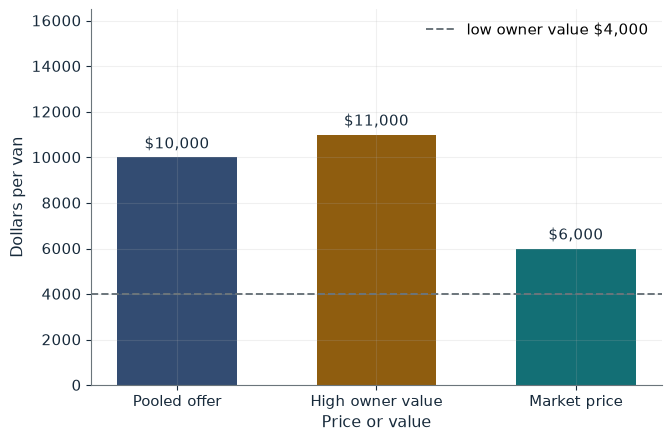

Pooled offer       $10,000
Equilibrium price  $6,000
Vans that trade    50 low-quality vans
Lost surplus       $150,000

Worked steps:
  1. Pooled offer = 0.5(6,000) + 0.5(14,000) = 10,000
  2. 10,000 < 11,000: high owners withdraw
  3. Price falls to the low-quality buyer value 6,000 (above the 4,000 reservation)
  4. Lost surplus = 50(14,000 - 11,000) = 150,000

With 50 high-quality and 50 low-quality vans, the pooled offer is 0.5(6,000) + 0.5(14,000) = 10,000. The pooled offer 10,000 is below the high owners' 11,000, so they keep their vans. Buyers price the remaining low-quality pool at 6,000 and 50 low vans trade. Lost surplus is 50(14,000 - 11,000) = 150,000.


In [2]:
show(lemons_picture(s_high=11_000, share=0.5))

Change one input, `share`, and hold the others at the book's values:

In [3]:
sweep(lemons_picture, 'share', [0.3, 0.5, 0.7], {'s_high': 11000}, ['Pooled offer', 'Equilibrium price', 'Lost surplus'])

share | Pooled offer | Equilibrium price | Lost surplus
0.3 | $8,400 | $6,000 | $90,000
0.5 | $10,000 | $6,000 | $150,000
0.7 | $11,600 | $11,600 | $0


At the book values the pooled offer of \$10,000 is below the \$11,000 the good owners keep, so only the 50 low vans trade at \$6,000 and \$150,000 of surplus is lost. With 70 percent good vans the pooled offer of \$11,600 keeps everyone in.

## 2. Asymmetric information and adverse selection

$$\pi_0=\frac{50(\$1{,}000)+50(\$3{,}000)}{100}=\$2{,}000, \qquad \pi_1=\$3{,}000, \qquad 100(\$100)=\$10{,}000$$

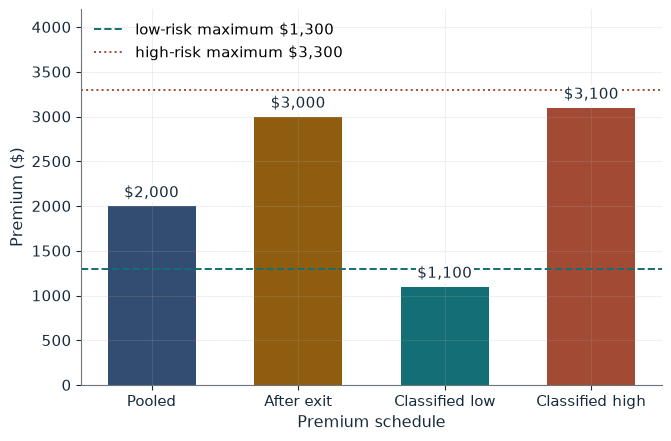

Pooled premium                $2,000
Equilibrium premium           $3,000
Low-risk take-up, pooled      0
Low-risk take-up, classified  50
Classification cost           $10,000

Worked steps:
  1. Pooled premium = (50(1,000) + 50(3,000)) / 100 = 2,000
  2. Low risks: 1,300 < 2,000, equilibrium premium 3,000
  3. Classified low premium = 1,000 + 100 = 1,100
  4. Classification cost = 100(100) = 10,000

Pooled premium = (50(1,000) + 50(3,000)) / 100 = 2,000. Low risks pay at most 1,300 < 2,000, so they leave and the premium rises to the high-risk claim, 3,000. Classification sets premiums 1,000 + 100 = 1,100 and 3,000 + 100 = 3,100; low risks enroll (1,100 <= 1,300) and high risks enroll (3,100 <= 3,300). It uses 100(100) = 10,000 of resources.


In [4]:
show(spiral_picture(w_low=1_300, cc=100))

Change one input, `cc`, and hold the others at the book's values:

In [5]:
sweep(spiral_picture, 'cc', [0, 100, 400], {'w_low': 1300}, ['Equilibrium premium', 'Low-risk take-up, classified', 'Classification cost'])

cc | Equilibrium premium | Low-risk take-up, classified | Classification cost
0 | $3,000 | 50 | $0
100 | $3,000 | 50 | $10,000
400 | $3,000 | 0 | $40,000


Low risks pay at most \$1,300, below the pooled \$2,000, so the premium rises to \$3,000. Classification at \$100 brings them back at \$1,100; at \$400 their premium of \$1,400 is too high.

## 3. Costly signaling

$$\$100{,}000-\$10{,}000=\$90{,}000, \qquad \$100{,}000-\$50{,}000=\$50{,}000$$

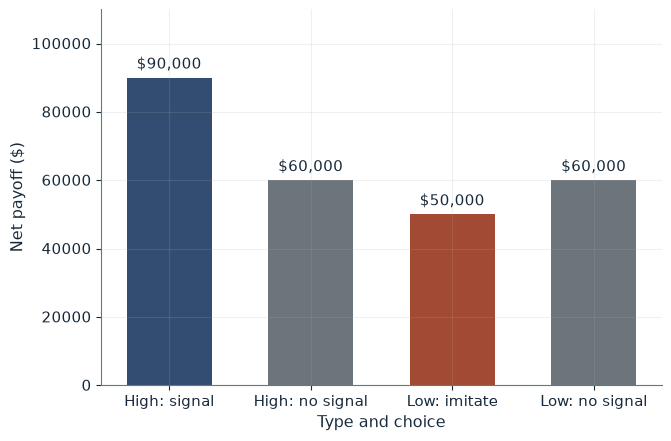

High type net with signal       $90,000
Low type payoff from imitation  $50,000
Separating                      yes

Worked steps:
  1. High: 100,000 - 10,000 = 90,000 > 60,000
  2. Low: 100,000 - 50,000 = 50,000 < 60,000
  3. Separating: yes

High type: 100,000 - 10,000 = 90,000 > 60,000. Low type imitating: 100,000 - 50,000 = 50,000 < 60,000. The credential separates the types. Imitation breaks even at a low-type cost of 100,000 - 60,000 = 40,000.


In [6]:
show(signal_picture(c_low=50_000, c_high=10_000))

Change one input, `c_low`, and hold the others at the book's values:

In [7]:
sweep(signal_picture, 'c_low', [30000, 40000, 50000], {'c_high': 10000}, ['Low type payoff from imitation', 'Separating'])

c_low | Low type payoff from imitation | Separating
30000 | $70,000 | no
40000 | $60,000 | yes, weakly (low type indifferent)
50000 | $50,000 | yes


The credential separates when it costs the low type more than the 40,000 wage gain; at exactly 40,000 the low type is indifferent.

## 4. Screening and self-selection

$$\$225+0.10(\$500)=\$275, \qquad \$225+0.40(\$500)=\$425$$

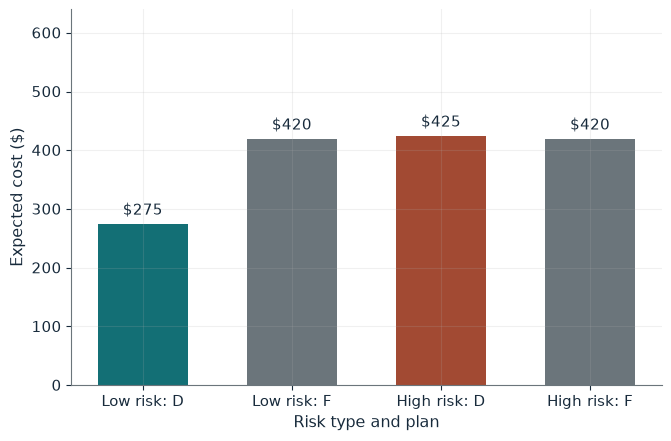

Low risk cost under D   $275
High risk cost under D  $425
Low risk chooses        Plan D
High risk chooses       Plan F
Separating              yes

Worked steps:
  1. Low: 225 + 0.10(500) = 275 < 420, Plan D
  2. High: 225 + 0.40(500) = 425 > 420, Plan F
  3. Separating: yes

Low risk under D: 225 + 0.10(500) = 275 against 420, so it chooses Plan D. High risk under D: 225 + 0.40(500) = 425 against 420, so it chooses Plan F. The menu separates: each type picks a different plan.


In [8]:
show(menu_picture(prem=225, ded=500))

Change one input, `prem`, and hold the others at the book's values:

In [9]:
sweep(menu_picture, 'prem', [175, 225, 250], {'ded': 500}, ['Low risk cost under D', 'High risk cost under D', 'Separating'])

prem | Low risk cost under D | High risk cost under D | Separating
175 | $225 | $375 | no
225 | $275 | $425 | yes
250 | $300 | $450 | yes


At \$225 the low risk pays \$275 under D and the high risk \$425, above Plan F's \$420, so the menu separates. At \$175 both choose D.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

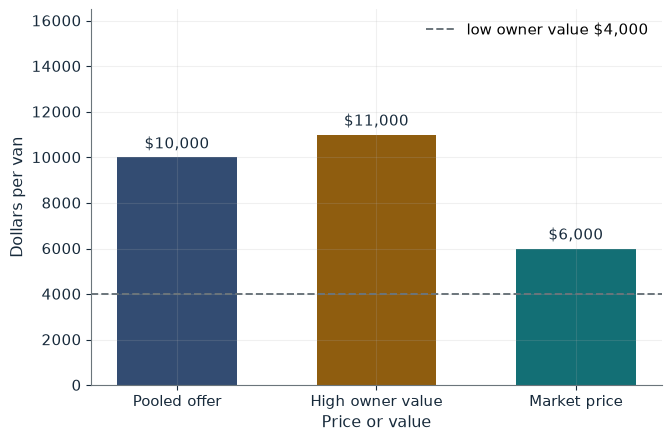

Pooled offer       $10,000
Equilibrium price  $6,000
Vans that trade    50 low-quality vans
Lost surplus       $150,000

Worked steps:
  1. Pooled offer = 0.5(6,000) + 0.5(14,000) = 10,000
  2. 10,000 < 11,000: high owners withdraw
  3. Price falls to the low-quality buyer value 6,000 (above the 4,000 reservation)
  4. Lost surplus = 50(14,000 - 11,000) = 150,000

With 50 high-quality and 50 low-quality vans, the pooled offer is 0.5(6,000) + 0.5(14,000) = 10,000. The pooled offer 10,000 is below the high owners' 11,000, so they keep their vans. Buyers price the remaining low-quality pool at 6,000 and 50 low vans trade. Lost surplus is 50(14,000 - 11,000) = 150,000.


In [10]:
show(lemons_picture(s_high=11_000, share=0.5))

## Practice

**1.** With 70 percent high quality, does the pool survive?

<details><summary>Answer</summary>

0.3(6,000) + 0.7(14,000) = 11,600 > 11,000, so all vans trade at 11,600.

</details>

**2.** At what low-type credential cost does imitation just break even?

<details><summary>Answer</summary>

100,000 - c = 60,000 gives c = 40,000.

</details>

**3.** With a \$175 premium and a \$700 deductible, does the menu separate?

<details><summary>Answer</summary>

Low: 175 + 70 = 245 < 420, Plan D; high: 175 + 280 = 455 > 420, Plan F. It separates.

</details>